# HMK / 02 — Longer windows for the intraday chains: 1 h on 40 / 60 bars, 15 m on 60 / 80 bars; set bands vs HMM (descriptive)

Protocol: [`HMK 004`](../../discussions/MNQ_Hierarchical_Markov/004_claude_hmk02_longer_windows.md). Code: `src/equity_trading/hmk.py`. **No trading test.**

- **Daily reference:** 20 days, ±5% (as in 01).
- **Window return** S_t = sum of the last W bar log returns (bar t included): 1 h W = 40, 60; 15 m W = 60, 80.
- **(a) Set band:** the daily ±5% / 20 days scaled by √time to W bars: 1 h ±1.47% (40), ±1.81% (60); 15 m ±0.90% (60), ±1.04% (80).
- **(b) HMM:** 3-state Gaussian HMM on S_t, fitted on the window; states = argmax of the causal filtered probabilities. The HMM's state means are the bull / bear returns it 'expects'; the midpoints between them are its implied thresholds.
- **Per case:** state shares, counts, P, persistence vs shuffled returns (same W, same rule or refitted HMM) and vs non-overlapping W-bar blocks, P^2/3/5/20, stationary distribution, run lengths, next-bar up share by state (descriptive).
- **Window:** 2020-01 – 2023-06 and halves 2020-01 – 2021-09 / 2021-10 – 2023-06.

Environment: `HMK_SYNTHETIC=1` (random-walk smoke run), `HMK_SYNTH_DIR`.

In [1]:
import json, os, sys, tempfile, warnings
import datetime as dt
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=RuntimeWarning)
SYNTHETIC = os.environ.get("HMK_SYNTHETIC") == "1"
if SYNTHETIC:
    os.environ["EQUITY_TRADING_DIR"] = os.environ.get("HMK_SYNTH_DIR") or tempfile.mkdtemp(prefix="hmk_")
    os.environ["HMK_SYNTH_DIR"] = os.environ["EQUITY_TRADING_DIR"]

REPO = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(REPO / "src"))
from equity_trading import hmk as H
from equity_trading import micro_bars as MB

D = dt.date
CFG = H.HMKConfig()
if SYNTHETIC:
    WINDOWS = {"all": (D(2020, 1, 1), D(2021, 6, 30)), "H1": (D(2020, 1, 1), D(2020, 9, 30)), "H2": (D(2020, 10, 1), D(2021, 6, 30))}
    if not (Path(os.environ["EQUITY_TRADING_DIR"]) / "Databento").exists():
        H.write_synthetic(os.environ["EQUITY_TRADING_DIR"], CFG.load_start, WINDOWS["all"][1], effect=0.0)
    N_NULL_RULE, N_NULL_HMM = 30, 3
else:
    WINDOWS = {"all": (D(2020, 1, 1), D(2023, 6, 30)), "H1": (D(2020, 1, 1), D(2021, 9, 30)), "H2": (D(2021, 10, 1), D(2023, 6, 30))}
    N_NULL_RULE, N_NULL_HMM = 200, 20
CASES = [("1d", 20)] + [("1h", w) for w in (40, 60)] + [("15m", w) for w in (60, 80)]
OUT = Path("02"); OUT.mkdir(exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 50)
print("engine", H.HMK_VERSION, "| synthetic random walk" if SYNTHETIC else "| real data")
print({f"{t} W={w}": f"±{100 * H.band_for_window(t, w):.2f}%" for t, w in CASES})

engine 0.1.0 | real data
{'1d W=20': '±5.00%', '1h W=40': '±1.47%', '1h W=60': '±1.81%', '15m W=60': '±0.90%', '15m W=80': '±1.04%'}


In [2]:
m1 = MB.load_1m(CFG.root, CFG.load_start, WINDOWS["all"][1] + dt.timedelta(days=1))
BARS = H.session_bars(m1, CFG)
del m1
def series(tier, a, b):
    x = BARS[tier]
    t = pd.to_datetime(x.trade_date).dt.date
    return x[t <= b].ret_bp.to_numpy(float), (t[t <= b] >= a).to_numpy()

REP = {}
for tier, w in CASES:
    for win in WINDOWS:
        r, inwin = series(tier, *WINDOWS[win])
        full = win == "all"
        REP[(tier, w, "band", win)] = H.chain_report(r, w, H.band_for_window(tier, w), n_null=N_NULL_RULE if full else 0, mask=inwin)
        if tier != "1d":
            REP[(tier, w, "hmm", win)] = H.hmm_report(r, w, inwin, CFG, n_null=N_NULL_HMM if full else 0)
    print(tier, w, "done", flush=True)

1d 20 done
1h 40 done
1h 60 done
15m 60 done
15m 80 done


In [3]:
SUM = []
for (t, w, kind, win), r in REP.items():
    for s in H.STATE_NAMES:
        SUM.append({"tier": t, "W": w, "states": kind, "window": win, "state": s, "n_bars": r["n_bars"], "share": r["share"][s],
                    "p_stay": r["diag"][s], "p_stay_shuffled": r.get("null_shuffle_diag_mean", pd.Series(dtype=float)).get(s, np.nan),
                    "p_stay_shuffled_q95": r.get("null_shuffle_diag_q95", pd.Series(dtype=float)).get(s, np.nan),
                    "p_stay_nonoverlap": r["P_nonoverlap"].loc[s, s], "expected_duration_bars": r["expected_duration"][s],
                    "mean_run_bars": r["runs"].loc[s, "mean"], "stationary": r["stationary"][s],
                    "next_bar_up_share": r["next_bar_up_share"][s], "next_bar_n": r["next_bar_n"][s],
                    "band_pct": 100 * r["band"] if "band" in r else np.nan,
                    "hmm_mean_pct": r["state_mean_pct"][s] if "state_mean_pct" in r else np.nan,
                    "hmm_sd_pct": r["state_sd_pct"][s] if "state_sd_pct" in r else np.nan})
SUM = pd.DataFrame(SUM); SUM.to_csv(OUT / "02_summary.csv", index=False)
mats = []
for (t, w, kind, win), r in REP.items():
    for name, M in (("P", r["P"]), ("counts", r["counts"]), ("P_nonoverlap", r["P_nonoverlap"])) + tuple((f"P^{n}", m) for n, m in r["P_steps"].items()):
        mats.append(M.reset_index(names="from").assign(tier=t, W=w, states=kind, window=win, matrix=name))
pd.concat(mats).to_csv(OUT / "02_matrices.csv", index=False)
HMMP = {f"{t}_W{w}": {"mean_pct": r["state_mean_pct"].round(4).to_dict(), "sd_pct": r["state_sd_pct"].round(4).to_dict(),
                      "boundaries_pct": [round(b, 4) for b in r["boundaries_pct"]]}
        for (t, w, kind, win), r in REP.items() if kind == "hmm" and win == "all"}
json.dump(HMMP, open(OUT / "02_hmm_states.json", "w"), indent=1)
print(json.dumps(HMMP, indent=1))

{
 "1h_W40": {
  "mean_pct": {
   "bear": -2.362,
   "side": 0.209,
   "bull": 2.4232
  },
  "sd_pct": {
   "bear": 1.5183,
   "side": 0.6174,
   "bull": 1.369
  },
  "boundaries_pct": [
   -1.0765,
   1.3161
  ]
 },
 "1h_W60": {
  "mean_pct": {
   "bear": -2.265,
   "side": 0.6907,
   "bull": 3.2048
  },
  "sd_pct": {
   "bear": 1.761,
   "side": 0.6787,
   "bull": 1.4776
  },
  "boundaries_pct": [
   -0.7872,
   1.9477
  ]
 },
 "15m_W60": {
  "mean_pct": {
   "bear": -0.6502,
   "side": -0.1115,
   "bull": 0.9019
  },
  "sd_pct": {
   "bear": 2.1929,
   "side": 0.3361,
   "bull": 0.4098
  },
  "boundaries_pct": [
   -0.3809,
   0.3952
  ]
 },
 "15m_W80": {
  "mean_pct": {
   "bear": -0.7359,
   "side": -0.1892,
   "bull": 1.0162
  },
  "sd_pct": {
   "bear": 2.5549,
   "side": 0.3925,
   "bull": 0.4653
  },
  "boundaries_pct": [
   -0.4625,
   0.4135
  ]
 }
}


## 1d, W = 20

In [4]:
for kind in ('band',):
    r = REP[("1d", 20, kind, "all")]
    head = f"set band ±{100 * r['band']:.2f}%" if kind == "band" else f"HMM: state means {r['state_mean_pct'].round(3).to_dict()} %, boundaries {[round(b, 3) for b in r['boundaries_pct']]} %"
    print(f"=== 1d W=20 | {head} | bars {r['n_bars']} | non-overlapping blocks {r['n_blocks']}")
    print("state share:", r["share"].round(3).to_dict(), "| stationary:", r["stationary"].round(3).to_dict())
    print("counts"); display(r["counts"].astype(int))
    print("P(next bar's state | this bar's state)"); display(r["P"].round(3))
    print("persistence: diagonal vs shuffled-return reference vs non-overlapping blocks")
    display(pd.DataFrame({"p_stay": r["diag"], "shuffled_mean": r["null_shuffle_diag_mean"], "shuffled_q95": r["null_shuffle_diag_q95"],
                          "non_overlapping": np.diag(r["P_nonoverlap"]), "share": r["share"], "expected_duration": r["expected_duration"]}).round(3))
    print("P^2, P^3, P^5, P^20"); display(pd.concat({f"P^{n}": m for n, m in r["P_steps"].items()}).round(3))
    print("runs (bars)"); display(r["runs"].round(2))
    print("halves: p_stay / share"); display(SUM[(SUM.tier == "1d") & (SUM.W == 20) & (SUM.states == kind)].pivot_table(index="state", columns="window", values=["p_stay", "share"]).round(3))
    print("descriptive: share of next bars that close up, by state"); display(pd.DataFrame({"up_share": r["next_bar_up_share"], "n": r["next_bar_n"]}).round(4))

=== 1d W=20 | set band ±5.00% | bars 882 | non-overlapping blocks 45
state share: {'bear': 0.175, 'side': 0.493, 'bull': 0.332} | stationary: {'bear': 0.176, 'side': 0.496, 'bull': 0.328}
counts


,bear,side,bull
bear,131,23,0
side,23,360,51
bull,0,52,241


P(next bar's state | this bar's state)


,bear,side,bull
bear,0.851,0.149,0.000
side,0.053,0.829,0.118
bull,0.000,0.177,0.823


persistence: diagonal vs shuffled-return reference vs non-overlapping blocks


,p_stay,shuffled_mean,shuffled_q95,non_overlapping,share,expected_duration
bear,0.851,0.825,0.882,0.286,0.175,6.696
side,0.829,0.851,0.879,0.435,0.493,5.865
bull,0.823,0.866,0.902,0.214,0.332,5.635


... (4 outputs left out)

halves: p_stay / share


p_stay                share              
window     H1     H2    all     H1     H2    all
state                                           
bear    0.786  0.874  0.851  0.095  0.258  0.175
bull    0.795  0.861  0.823  0.378  0.284  0.332
side    0.815  0.847  0.829  0.527  0.458  0.493

descriptive: share of next bars that close up, by state


,up_share,n
bear,0.5232,151
side,0.5377,424
bull,0.5567,291


## 1h, W = 40

In [5]:
for kind in ('band', 'hmm'):
    r = REP[("1h", 40, kind, "all")]
    head = f"set band ±{100 * r['band']:.2f}%" if kind == "band" else f"HMM: state means {r['state_mean_pct'].round(3).to_dict()} %, boundaries {[round(b, 3) for b in r['boundaries_pct']]} %"
    print(f"=== 1h W=40 | {head} | bars {r['n_bars']} | non-overlapping blocks {r['n_blocks']}")
    print("state share:", r["share"].round(3).to_dict(), "| stationary:", r["stationary"].round(3).to_dict())
    print("counts"); display(r["counts"].astype(int))
    print("P(next bar's state | this bar's state)"); display(r["P"].round(3))
    print("persistence: diagonal vs shuffled-return reference vs non-overlapping blocks")
    display(pd.DataFrame({"p_stay": r["diag"], "shuffled_mean": r["null_shuffle_diag_mean"], "shuffled_q95": r["null_shuffle_diag_q95"],
                          "non_overlapping": np.diag(r["P_nonoverlap"]), "share": r["share"], "expected_duration": r["expected_duration"]}).round(3))
    print("P^2, P^3, P^5, P^20"); display(pd.concat({f"P^{n}": m for n, m in r["P_steps"].items()}).round(3))
    print("runs (bars)"); display(r["runs"].round(2))
    print("halves: p_stay / share"); display(SUM[(SUM.tier == "1h") & (SUM.W == 40) & (SUM.states == kind)].pivot_table(index="state", columns="window", values=["p_stay", "share"]).round(3))
    print("descriptive: share of next bars that close up, by state"); display(pd.DataFrame({"up_share": r["next_bar_up_share"], "n": r["next_bar_n"]}).round(4))

=== 1h W=40 | set band ±1.47% | bars 20286 | non-overlapping blocks 508
state share: {'bear': 0.187, 'side': 0.576, 'bull': 0.236} | stationary: {'bear': 0.187, 'side': 0.576, 'bull': 0.236}
counts


,bear,side,bull
bear,3414,386,2
side,384,10812,495
bull,4,493,4295


P(next bar's state | this bar's state)


,bear,side,bull
bear,0.898,0.102,0.001
side,0.033,0.925,0.042
bull,0.001,0.103,0.896


persistence: diagonal vs shuffled-return reference vs non-overlapping blocks


,p_stay,shuffled_mean,shuffled_q95,non_overlapping,share,expected_duration
bear,0.898,0.899,0.909,0.222,0.187,9.799
side,0.925,0.909,0.915,0.605,0.576,13.300
bull,0.896,0.906,0.915,0.190,0.236,9.642


... (18 outputs left out)

halves: p_stay / share


p_stay                share              
window     H1     H2    all     H1     H2    all
state                                           
bear    0.961  0.953  0.964  0.252  0.251  0.274
bull    0.949  0.968  0.960  0.314  0.397  0.286
side    0.954  0.931  0.953  0.435  0.352  0.440

descriptive: share of next bars that close up, by state


,up_share,n
bear,0.5142,5512
side,0.5276,8796
bull,0.5254,5733


## 1h, W = 60

In [6]:
for kind in ('band', 'hmm'):
    r = REP[("1h", 60, kind, "all")]
    head = f"set band ±{100 * r['band']:.2f}%" if kind == "band" else f"HMM: state means {r['state_mean_pct'].round(3).to_dict()} %, boundaries {[round(b, 3) for b in r['boundaries_pct']]} %"
    print(f"=== 1h W=60 | {head} | bars {r['n_bars']} | non-overlapping blocks {r['n_blocks']}")
    print("state share:", r["share"].round(3).to_dict(), "| stationary:", r["stationary"].round(3).to_dict())
    print("counts"); display(r["counts"].astype(int))
    print("P(next bar's state | this bar's state)"); display(r["P"].round(3))
    print("persistence: diagonal vs shuffled-return reference vs non-overlapping blocks")
    display(pd.DataFrame({"p_stay": r["diag"], "shuffled_mean": r["null_shuffle_diag_mean"], "shuffled_q95": r["null_shuffle_diag_q95"],
                          "non_overlapping": np.diag(r["P_nonoverlap"]), "share": r["share"], "expected_duration": r["expected_duration"]}).round(3))
    print("P^2, P^3, P^5, P^20"); display(pd.concat({f"P^{n}": m for n, m in r["P_steps"].items()}).round(3))
    print("runs (bars)"); display(r["runs"].round(2))
    print("halves: p_stay / share"); display(SUM[(SUM.tier == "1h") & (SUM.W == 60) & (SUM.states == kind)].pivot_table(index="state", columns="window", values=["p_stay", "share"]).round(3))
    print("descriptive: share of next bars that close up, by state"); display(pd.DataFrame({"up_share": r["next_bar_up_share"], "n": r["next_bar_n"]}).round(4))

=== 1h W=60 | set band ±1.81% | bars 20286 | non-overlapping blocks 339
state share: {'bear': 0.183, 'side': 0.582, 'bull': 0.235} | stationary: {'bear': 0.183, 'side': 0.582, 'bull': 0.235}
counts


,bear,side,bull
bear,3358,353,1
side,354,11005,449
bull,0,450,4315


P(next bar's state | this bar's state)


,bear,side,bull
bear,0.905,0.095,0.000
side,0.030,0.932,0.038
bull,0.000,0.094,0.906


persistence: diagonal vs shuffled-return reference vs non-overlapping blocks


,p_stay,shuffled_mean,shuffled_q95,non_overlapping,share,expected_duration
bear,0.905,0.918,0.927,0.200,0.183,10.486
side,0.932,0.925,0.930,0.660,0.582,14.705
bull,0.906,0.925,0.933,0.231,0.235,10.589


... (18 outputs left out)

halves: p_stay / share


p_stay                share              
window     H1     H2    all     H1     H2    all
state                                           
bear    0.961  0.962  0.975  0.270  0.224  0.369
bull    0.960  0.978  0.966  0.364  0.418  0.241
side    0.951  0.951  0.956  0.367  0.358  0.390

descriptive: share of next bars that close up, by state


,up_share,n
bear,0.5182,7410
side,0.5291,7806
bull,0.5217,4825


## 15m, W = 60

In [7]:
for kind in ('band', 'hmm'):
    r = REP[("15m", 60, kind, "all")]
    head = f"set band ±{100 * r['band']:.2f}%" if kind == "band" else f"HMM: state means {r['state_mean_pct'].round(3).to_dict()} %, boundaries {[round(b, 3) for b in r['boundaries_pct']]} %"
    print(f"=== 15m W=60 | {head} | bars {r['n_bars']} | non-overlapping blocks {r['n_blocks']}")
    print("state share:", r["share"].round(3).to_dict(), "| stationary:", r["stationary"].round(3).to_dict())
    print("counts"); display(r["counts"].astype(int))
    print("P(next bar's state | this bar's state)"); display(r["P"].round(3))
    print("persistence: diagonal vs shuffled-return reference vs non-overlapping blocks")
    display(pd.DataFrame({"p_stay": r["diag"], "shuffled_mean": r["null_shuffle_diag_mean"], "shuffled_q95": r["null_shuffle_diag_q95"],
                          "non_overlapping": np.diag(r["P_nonoverlap"]), "share": r["share"], "expected_duration": r["expected_duration"]}).round(3))
    print("P^2, P^3, P^5, P^20"); display(pd.concat({f"P^{n}": m for n, m in r["P_steps"].items()}).round(3))
    print("runs (bars)"); display(r["runs"].round(2))
    print("halves: p_stay / share"); display(SUM[(SUM.tier == "15m") & (SUM.W == 60) & (SUM.states == kind)].pivot_table(index="state", columns="window", values=["p_stay", "share"]).round(3))
    print("descriptive: share of next bars that close up, by state"); display(pd.DataFrame({"up_share": r["next_bar_up_share"], "n": r["next_bar_n"]}).round(4))

=== 15m W=60 | set band ±0.90% | bars 81144 | non-overlapping blocks 1353
state share: {'bear': 0.183, 'side': 0.607, 'bull': 0.21} | stationary: {'bear': 0.183, 'side': 0.607, 'bull': 0.21}
counts


,bear,side,bull
bear,13638,1235,6
side,1237,46550,1464
bull,4,1465,15544


P(next bar's state | this bar's state)


,bear,side,bull
bear,0.917,0.083,0.000
side,0.025,0.945,0.030
bull,0.000,0.086,0.914


persistence: diagonal vs shuffled-return reference vs non-overlapping blocks


,p_stay,shuffled_mean,shuffled_q95,non_overlapping,share,expected_duration
bear,0.917,0.921,0.926,0.258,0.183,11.990
side,0.945,0.928,0.931,0.640,0.607,18.234
bull,0.914,0.924,0.930,0.224,0.210,11.581


... (18 outputs left out)

halves: p_stay / share


p_stay                share              
window     H1     H2    all     H1     H2    all
state                                           
bear    0.968  0.968  0.969  0.284  0.280  0.285
bull    0.959  0.967  0.958  0.320  0.279  0.314
side    0.960  0.959  0.958  0.395  0.441  0.402

descriptive: share of next bars that close up, by state


,up_share,n
bear,0.5134,22617
side,0.5171,31707
bull,0.5156,24958


## 15m, W = 80

In [8]:
for kind in ('band', 'hmm'):
    r = REP[("15m", 80, kind, "all")]
    head = f"set band ±{100 * r['band']:.2f}%" if kind == "band" else f"HMM: state means {r['state_mean_pct'].round(3).to_dict()} %, boundaries {[round(b, 3) for b in r['boundaries_pct']]} %"
    print(f"=== 15m W=80 | {head} | bars {r['n_bars']} | non-overlapping blocks {r['n_blocks']}")
    print("state share:", r["share"].round(3).to_dict(), "| stationary:", r["stationary"].round(3).to_dict())
    print("counts"); display(r["counts"].astype(int))
    print("P(next bar's state | this bar's state)"); display(r["P"].round(3))
    print("persistence: diagonal vs shuffled-return reference vs non-overlapping blocks")
    display(pd.DataFrame({"p_stay": r["diag"], "shuffled_mean": r["null_shuffle_diag_mean"], "shuffled_q95": r["null_shuffle_diag_q95"],
                          "non_overlapping": np.diag(r["P_nonoverlap"]), "share": r["share"], "expected_duration": r["expected_duration"]}).round(3))
    print("P^2, P^3, P^5, P^20"); display(pd.concat({f"P^{n}": m for n, m in r["P_steps"].items()}).round(3))
    print("runs (bars)"); display(r["runs"].round(2))
    print("halves: p_stay / share"); display(SUM[(SUM.tier == "15m") & (SUM.W == 80) & (SUM.states == kind)].pivot_table(index="state", columns="window", values=["p_stay", "share"]).round(3))
    print("descriptive: share of next bars that close up, by state"); display(pd.DataFrame({"up_share": r["next_bar_up_share"], "n": r["next_bar_n"]}).round(4))

=== 15m W=80 | set band ±1.04% | bars 81144 | non-overlapping blocks 1015
state share: {'bear': 0.188, 'side': 0.592, 'bull': 0.22} | stationary: {'bear': 0.188, 'side': 0.592, 'bull': 0.22}
counts


,bear,side,bull
bear,14169,1075,1
side,1076,45670,1330
bull,0,1330,16492


P(next bar's state | this bar's state)


,bear,side,bull
bear,0.929,0.071,0.000
side,0.022,0.950,0.028
bull,0.000,0.075,0.925


persistence: diagonal vs shuffled-return reference vs non-overlapping blocks


,p_stay,shuffled_mean,shuffled_q95,non_overlapping,share,expected_duration
bear,0.929,0.932,0.937,0.228,0.188,14.168
side,0.950,0.937,0.940,0.662,0.592,19.982
bull,0.925,0.935,0.940,0.208,0.220,13.400


... (18 outputs left out)

halves: p_stay / share


p_stay                share              
window     H1     H2    all     H1     H2    all
state                                           
bear    0.973  0.978  0.974  0.272  0.298  0.280
bull    0.968  0.977  0.970  0.346  0.308  0.342
side    0.967  0.965  0.966  0.382  0.394  0.378

descriptive: share of next bars that close up, by state


,up_share,n
bear,0.5076,22280
side,0.5164,29827
bull,0.5213,27175


## Summary and heatmaps

share  p_stay  p_stay_shuffled  p_stay_nonoverlap  next_bar_up_share  hmm_mean_pct
tier W  states state                                                                                    
1d   20 band   bear   0.175   0.851            0.825              0.286              0.523           NaN
               side   0.493   0.829            0.851              0.435              0.538           NaN
               bull   0.332   0.823            0.866              0.214              0.557           NaN
1h   40 band   bear   0.187   0.898            0.899              0.222              0.516           NaN
               side   0.576   0.925            0.909              0.605              0.524           NaN
               bull   0.236   0.896            0.906              0.190              0.526           NaN
        hmm    bear   0.274   0.964            0.960              0.359              0.514        -2.362
               side   0.440   0.953            0.938              0.527              0.528         0.209
               bull   0.286   0.960            0.959              0.261              0.525         2.423
     60 band   bear   0.183   0.905            0.918              0.200              0.520           NaN
               side   0.582   0.932            0.925              0.660              0.528           NaN
               bull   0.235   0.906            0.925              0.231              0.514           NaN
        hmm    bear   0.369   0.975            0.969              0.446              0.518        -2.265
               side   0.390   0.956            0.950              0.562              0.529         0.691
               bull   0.241   0.966            0.970              0.175              0.522         3.205
15m  60 band   bear   0.183   0.917            0.921              0.258              0.516           NaN
               side   0.607   0.945            0.928              0.640              0.517           NaN
               bull   0.210   0.914            0.924              0.224              0.512           NaN
        hmm    bear   0.285   0.969            0.970              0.407              0.513        -0.650
               side   0.402   0.958            0.952              0.449              0.517        -0.112
               bull   0.314   0.958            0.970              0.331              0.516         0.902
     80 band   bear   0.188   0.929            0.932              0.228              0.508           NaN
               side   0.592   0.950            0.937              0.662              0.520           NaN
               bull   0.220   0.925            0.935              0.208              0.511           NaN
        hmm    bear   0.280   0.974            0.976              0.371              0.508        -0.736
               side   0.378   0.966            0.959              0.421              0.516        -0.189
               bull   0.342   0.970            0.975              0.342              0.521         1.016

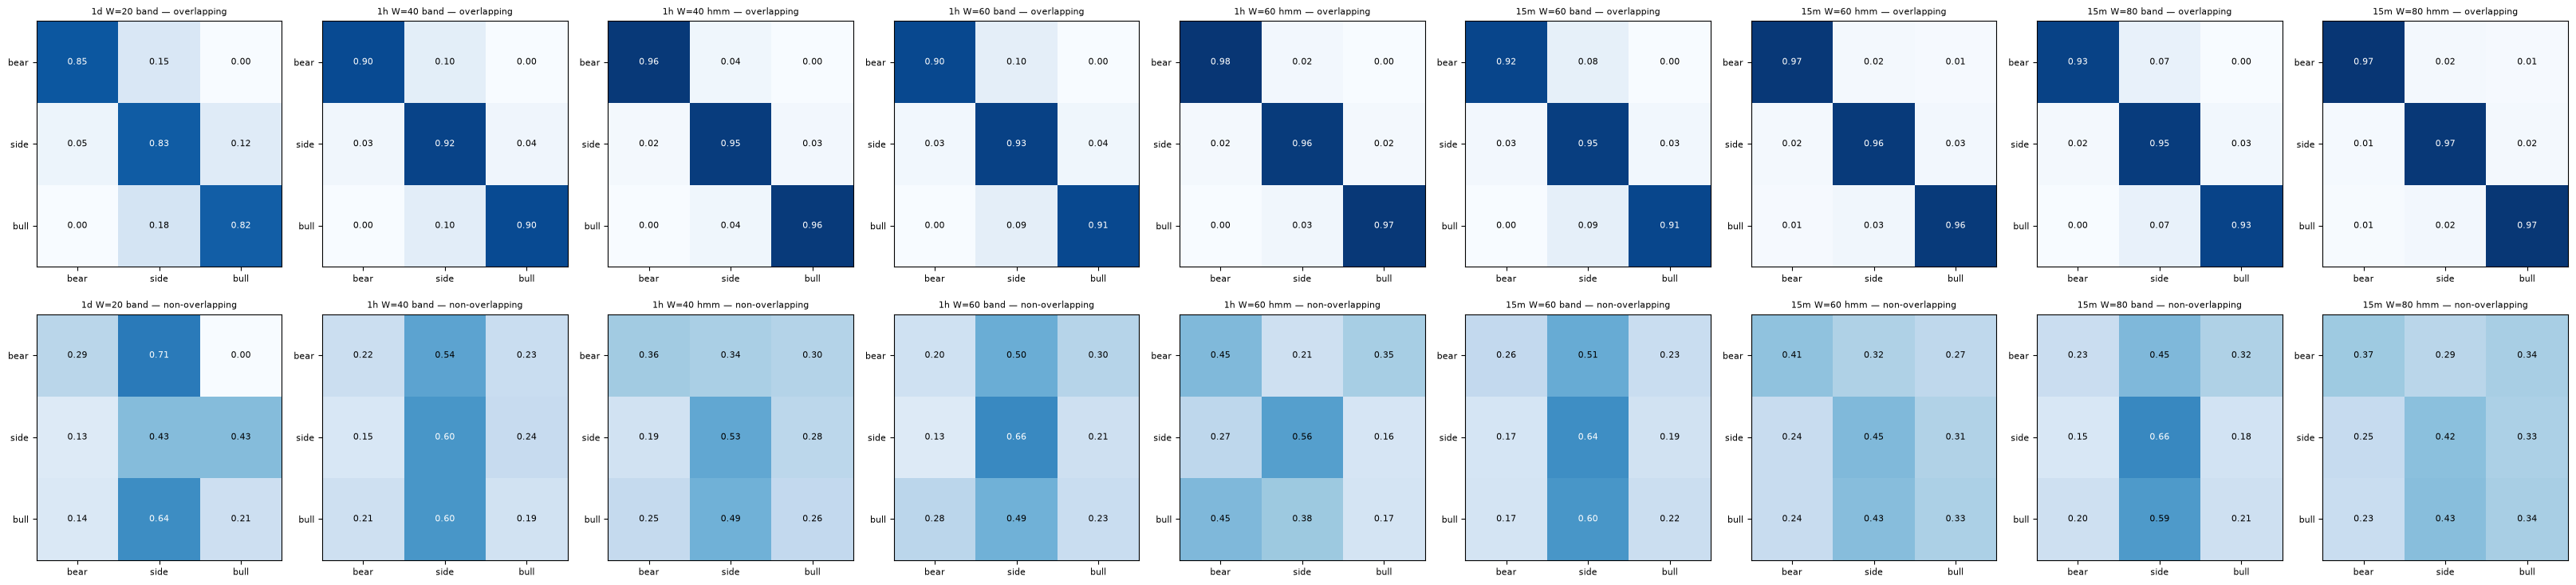

In [9]:
display(SUM[SUM.window == "all"].pivot_table(index=["tier", "W", "states", "state"],
        values=["share", "p_stay", "p_stay_shuffled", "p_stay_nonoverlap", "next_bar_up_share", "hmm_mean_pct"], sort=False).round(3))
keys = [k for k in REP if k[3] == "all"]
fig, ax = plt.subplots(2, len(keys), figsize=(3.6 * len(keys), 7.5))
for j, k in enumerate(keys):
    for i, (name, M) in enumerate((("overlapping", REP[k]["P"]), ("non-overlapping", REP[k]["P_nonoverlap"]))):
        a = ax[i, j]; v = M.to_numpy(float); a.imshow(v, vmin=0, vmax=1, cmap="Blues")
        for (p, q), x in np.ndenumerate(v):
            a.text(q, p, f"{x:.2f}" if np.isfinite(x) else "-", ha="center", va="center", color="k" if not np.isfinite(x) or x < 0.6 else "w", fontsize=8)
        a.set_xticks(range(3), H.STATE_NAMES, fontsize=8); a.set_yticks(range(3), H.STATE_NAMES, fontsize=8)
        a.set_title(f"{k[0]} W={k[1]} {k[2]} — {name}", fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "02_matrices.png", dpi=110); plt.show()
json.dump({"version": H.HMK_VERSION, "synthetic": SYNTHETIC, "windows": {k: [str(a), str(b)] for k, (a, b) in WINDOWS.items()},
           "cases": CASES, "bands_pct": {f"{t}_W{w}": 100 * H.band_for_window(t, w) for t, w in CASES},
           "n_null_rule": N_NULL_RULE, "n_null_hmm": N_NULL_HMM}, open(OUT / "02_run.json", "w"), indent=1)